# Báo Cáo Thực Nghiệm: Mạng Tích Chập 1D (1D CNN) Thuần NumPy Cho Phân Loại Văn Bản
## Bài Toán: Phân Loại Cảm Xúc Bình Luận Khách Hàng (NLP Sentiment Classification)
**Học phần:** Phát triển Hệ thống Thông minh (Intelligent System Development)  
**Nhiệm vụ:** Assignment 04 - Xây dựng mô hình 1D CNN văn bản (Slide 11: Tokens → Embedding → Conv1D → ReLU → Pooling → Dense → Sigmoid) thuần từ đầu  
**Dữ liệu:** `Womens Clothing E-Commerce Reviews.csv` (23,486 đánh giá sản phẩm)


In [1]:
import os
import re
import time
import json
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.size'] = 11


### 1. Đọc Dữ Liệu & Khảo Sát
Tập dữ liệu gồm các đánh giá mua sắm trực tuyến với nhãn mục tiêu `Recommended IND` (1: Khuyến nghị / Tích cực, 0: Không khuyến nghị / Tiêu cực).


In [2]:
DATA_PATH = "../../../Assigment 02/customer_behavior/data/Womens Clothing E-Commerce Reviews.csv"
if not os.path.exists(DATA_PATH):
    DATA_PATH = "src/Assigment 02/customer_behavior/data/Womens Clothing E-Commerce Reviews.csv"

df_raw = pd.read_csv(DATA_PATH)
df_clean = df_raw.dropna(subset=['Review Text', 'Recommended IND']).copy()
df_clean['Recommended IND'] = df_clean['Recommended IND'].astype(int)

print(f"Kích thước sau làm sạch: {df_clean.shape[0]:,} bình luận hợp lệ.")
print(df_clean[['Review Text', 'Recommended IND']].head(3))


Kích thước sau làm sạch: 22,641 bình luận hợp lệ.
                                         Review Text  Recommended IND
0  Absolutely wonderful - silky and sexy and comf...                1
1  Love this dress!  it's sooo pretty.  i happene...                1
2  I had such high hopes for this dress and reall...                0


### 2. Tiền Xử Lý Văn Bản & Xây Dựng Từ Điển (Vocabulary)
1. Chuẩn hóa: Viết thường, lọc ký tự đặc biệt, tách từ bằng Regex.
2. Xây dựng từ điển chứa 3,000 từ xuất hiện phổ biến nhất (`vocab_size = 3000`).
3. Đệm hoặc cắt chuỗi về độ dài cố định `max_len = 50` từ.


In [3]:
def clean_text(text):
    text = str(text).lower()
    tokens = re.findall(r'[a-zA-Z]+', text)
    return tokens

tokenized_texts = [clean_text(t) for t in df_clean['Review Text']]

# Đếm tần suất từ
word_counts = Counter(word for doc in tokenized_texts for word in doc)
VOCAB_SIZE = 3000
MAX_LEN = 50

# 0: <PAD>, 1: <UNK>
most_common = word_counts.most_common(VOCAB_SIZE - 2)
word2idx = {word: idx + 2 for idx, (word, _) in enumerate(most_common)}
word2idx['<PAD>'] = 0
word2idx['<UNK>'] = 1

def text_to_sequence(tokens, max_len=MAX_LEN):
    seq = [word2idx.get(w, 1) for w in tokens[:max_len]]
    if len(seq) < max_len:
        seq = seq + [0] * (max_len - len(seq))
    return seq

X_sequences = np.array([text_to_sequence(t) for t in tokenized_texts], dtype=np.int32)
y_labels = df_clean['Recommended IND'].values.astype(np.float32)

print(f"Ma trận chỉ số từ vựng: {X_sequences.shape}, Nhãn: {y_labels.shape}")


Ma trận chỉ số từ vựng: (22641, 50), Nhãn: (22641,)


### 3. Phân Chia Dữ Liệu Train/Test
Chia tỷ lệ 80% / 20% phân tầng theo nhãn cảm xúc với `random_state=42`.


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X_sequences, y_labels, test_size=0.20, random_state=RANDOM_SEED, stratify=y_labels
)

print(f"X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"X_test : {X_test.shape}, y_test : {y_test.shape}")


X_train: (18112, 50), y_train: (18112,)
X_test : (4529, 50), y_test : (4529,)


### 4. Triển Khai Toàn Bộ Các Lớp 1D CNN Văn Bản Thuần Từ Đầu (NumPy From Scratch)
Dưới đây là cài đặt chi tiết toàn bộ các lớp theo đúng kiến trúc Bài giảng số 4 (Slide 11: Tokens → Embedding → Conv1D → ReLU → Pooling → Dense → Sigmoid):
1. **`Embedding`**: Ánh xạ ma trận tra từ điển từ (Index Lookup) kích thước `(vocab_size, embed_dim)` sang tensor biểu diễn liên tục, tích lũy gradient qua `np.add.at`.
2. **`Conv1D`**: Quét kernel trượt qua chuỗi từ (trigram feature detector), hỗ trợ vector hóa với `sliding_window_view` và `np.einsum`.
3. **`MaxPool1D`**: Gom mẫu cực đại giảm số chiều biểu diễn.
4. **`ReLU`, `Flatten`, `Dense`, `Sigmoid`**: Các khối kích hoạt và phân lớp xác suất nhị phân.
5. **`Sequential1DCNN` & `AdamOptimizer`**: Quản lý chuỗi tầng và tối ưu hóa thích nghi đa tham số.
6. **`binary_cross_entropy`**: Hàm mất mát nhị phân.


In [5]:
# =====================================================================
# 1. CÀI ĐẶT CÁC LỚP MẠNG 1D CNN VĂN BẢN THUẦN TỪ ĐẦU BẰNG NUMPY
# =====================================================================

class Embedding:
    def __init__(self, vocab_size, embed_dim):
        self.vocab_size = vocab_size
        self.embed_dim = embed_dim
        # Khởi tạo Gaussian
        self.W = (np.random.randn(vocab_size, embed_dim) * 0.05).astype(np.float32)
        self.dW = np.zeros_like(self.W)
        self.indices = None

    def forward(self, indices):
        # indices: (batch_size, seq_len)
        # Returns: (batch_size, embed_dim, seq_len) cho Conv1D
        self.indices = indices
        return self.W[indices].transpose(0, 2, 1)

    def backward(self, dZ):
        # dZ: (batch_size, embed_dim, seq_len)
        dZ_orig = dZ.transpose(0, 2, 1)
        self.dW.fill(0)
        np.add.at(self.dW, self.indices, dZ_orig)
        return None


class Conv1D:
    def __init__(self, in_channels, out_channels, kernel_size=3, stride=1, padding=0):
        self.in_channels = in_channels
        self.out_channels = out_channels
        self.kernel_size = kernel_size
        self.stride = stride
        self.padding = padding

        # Khởi tạo He (Kaiming) Normal
        limit = np.sqrt(2.0 / (in_channels * kernel_size))
        self.W = np.random.randn(out_channels, in_channels, kernel_size).astype(np.float32) * limit
        self.b = np.zeros(out_channels, dtype=np.float32)

        self.dW = np.zeros_like(self.W)
        self.db = np.zeros_like(self.b)
        self.X = None
        self.sub_windows = None

    def forward(self, X):
        # X shape: (batch_size, in_channels, length)
        # Output shape: (batch_size, out_channels, length_out)
        self.X = X
        batch_size, in_channels, length = X.shape
        assert in_channels == self.in_channels, f"Expected {self.in_channels} channels, got {in_channels}"

        if self.padding > 0:
            X_pad = np.pad(X, ((0, 0), (0, 0), (self.padding, self.padding)), mode='constant')
        else:
            X_pad = X

        # Sử dụng sliding_window_view vector hóa tối đa
        self.sub_windows = np.lib.stride_tricks.sliding_window_view(
            X_pad, window_shape=self.kernel_size, axis=-1
        )[:, :, ::self.stride, :]

        # Einsum: N: batch, C: in_channels, L: out_len, K: kernel_size; F: out_channels
        out = np.einsum('nclk,fck->nfl', self.sub_windows, self.W) + self.b[:, None]
        return out

    def backward(self, dZ):
        # dZ shape: (batch_size, out_channels, length_out)
        # Returns dX shape: (batch_size, in_channels, length)
        self.db = np.sum(dZ, axis=(0, 2))
        self.dW = np.einsum('nfl,nclk->fck', dZ, self.sub_windows)

        batch_size, in_channels, length = self.X.shape
        L_out = dZ.shape[2]
        dX = np.zeros_like(self.X)

        for k in range(self.kernel_size):
            dX[:, :, k:k + L_out] += np.einsum('nfl,fc->ncl', dZ, self.W[:, :, k])

        return dX


class MaxPool1D:
    def __init__(self, pool_size=2):
        self.pool_size = pool_size
        self.X_shape = None
        self.X_reshaped = None
        self.out = None

    def forward(self, X):
        self.X_shape = X.shape
        batch_size, channels, length = X.shape
        L_out = length // self.pool_size

        self.X_reshaped = X[:, :, :L_out * self.pool_size].reshape(
            batch_size, channels, L_out, self.pool_size
        )
        self.out = np.max(self.X_reshaped, axis=-1)
        return self.out

    def backward(self, dZ):
        batch_size, channels, L_out = dZ.shape
        argmax_mask = (self.X_reshaped == self.out[:, :, :, None])
        counts = np.sum(argmax_mask, axis=-1, keepdims=True)
        counts[counts == 0] = 1.0
        mask = argmax_mask / counts

        dX_reshaped = dZ[:, :, :, None] * mask
        dX = np.zeros(self.X_shape, dtype=dZ.dtype)
        dX[:, :, :L_out * self.pool_size] = dX_reshaped.reshape(
            batch_size, channels, L_out * self.pool_size
        )
        return dX


class ReLU:
    def __init__(self):
        self.X = None

    def forward(self, X):
        self.X = X
        return np.maximum(0, X)

    def backward(self, dZ):
        return dZ * (self.X > 0)


class Flatten:
    def __init__(self):
        self.orig_shape = None

    def forward(self, X):
        self.orig_shape = X.shape
        return X.reshape(X.shape[0], -1)

    def backward(self, dZ):
        return dZ.reshape(self.orig_shape)


class Dense:
    def __init__(self, in_features, out_features):
        self.in_features = in_features
        self.out_features = out_features

        limit = np.sqrt(2.0 / in_features)
        self.W = np.random.randn(in_features, out_features).astype(np.float32) * limit
        self.b = np.zeros(out_features, dtype=np.float32)

        self.dW = np.zeros_like(self.W)
        self.db = np.zeros_like(self.b)
        self.X = None

    def forward(self, X):
        self.X = X
        return np.dot(X, self.W) + self.b

    def backward(self, dZ):
        self.db = np.sum(dZ, axis=0)
        self.dW = np.dot(self.X.T, dZ)
        return np.dot(dZ, self.W.T)


class Sigmoid:
    def __init__(self):
        self.out = None

    def forward(self, X):
        self.out = 1.0 / (1.0 + np.exp(-np.clip(X, -25.0, 25.0)))
        return self.out

    def backward(self, dZ):
        return dZ * self.out * (1.0 - self.out)


class Sequential1DCNN:
    def __init__(self, layers):
        self.layers = layers

    def forward(self, X):
        out = X
        for layer in self.layers:
            out = layer.forward(out)
        return out

    def backward(self, dLoss):
        grad = dLoss
        for layer in reversed(self.layers):
            grad = layer.backward(grad)
        return grad

    def get_trainable_layers(self):
        return [l for l in self.layers if hasattr(l, 'W')]


class AdamOptimizer:
    def __init__(self, trainable_layers, lr=0.001, beta1=0.9, beta2=0.999, eps=1e-8):
        self.layers = trainable_layers
        self.lr = lr
        self.beta1 = beta1
        self.beta2 = beta2
        self.eps = eps
        self.t = 0

        self.mW = [np.zeros_like(l.W) for l in self.layers]
        self.vW = [np.zeros_like(l.W) for l in self.layers]
        self.mb = [np.zeros_like(l.b) if hasattr(l, 'b') else None for l in self.layers]
        self.vb = [np.zeros_like(l.b) if hasattr(l, 'b') else None for l in self.layers]

    def step(self):
        self.t += 1
        for i, layer in enumerate(self.layers):
            self.mW[i] = self.beta1 * self.mW[i] + (1 - self.beta1) * layer.dW
            self.vW[i] = self.beta2 * self.vW[i] + (1 - self.beta2) * (layer.dW ** 2)
            m_hat = self.mW[i] / (1 - self.beta1 ** self.t)
            v_hat = self.vW[i] / (1 - self.beta2 ** self.t)
            layer.W -= self.lr * m_hat / (np.sqrt(v_hat) + self.eps)

            if hasattr(layer, 'b') and hasattr(layer, 'db'):
                self.mb[i] = self.beta1 * self.mb[i] + (1 - self.beta1) * layer.db
                self.vb[i] = self.beta2 * self.vb[i] + (1 - self.beta2) * (layer.db ** 2)
                m_hat_b = self.mb[i] / (1 - self.beta1 ** self.t)
                v_hat_b = self.vb[i] / (1 - self.beta2 ** self.t)
                layer.b -= self.lr * m_hat_b / (np.sqrt(v_hat_b) + self.eps)


def binary_cross_entropy(y_pred, y_true, eps=1e-7):
    y_pred = np.clip(y_pred, eps, 1.0 - eps)
    loss = -np.mean(y_true * np.log(y_pred) + (1.0 - y_true) * np.log(1.0 - y_pred))
    grad = (y_pred - y_true) / (y_pred * (1.0 - y_pred) * len(y_true))
    return loss, grad

print("Đã nạp toàn bộ các lớp 1D CNN Văn bản thuần NumPy thành công!")


Đã nạp toàn bộ các lớp 1D CNN Văn bản thuần NumPy thành công!


### 5. Khởi Tạo Kiến Trúc Mô Hình & Kiểm Tra Tham Số
Khởi tạo cấu trúc theo Slide 11:
`Tokens (50) -> Embedding(vocab=3000, dim=32) -> Conv1D(32 filters, kernel 3) -> ReLU -> MaxPool1D(2) -> Flatten -> Dense(16) -> ReLU -> Dense(1) -> Sigmoid`.
Phép tích chập với kernel=3 sẽ quét qua từng cụm 3 từ (trigram) liên tiếp để phát hiện mẫu ngữ cảnh cục bộ.


In [6]:
EMBED_DIM = 32

model = Sequential1DCNN([
    Embedding(vocab_size=VOCAB_SIZE, embed_dim=EMBED_DIM),   # Output: (batch, 32, 50)
    Conv1D(in_channels=EMBED_DIM, out_channels=32, kernel_size=3), # L_out = 50 - 3 + 1 = 48
    ReLU(),
    MaxPool1D(pool_size=2),                                  # L_out = 48 // 2 = 24
    Flatten(),                                               # 32 * 24 = 768
    Dense(in_features=768, out_features=16),
    ReLU(),
    Dense(in_features=16, out_features=1),
    Sigmoid()
])

trainable_layers = model.get_trainable_layers()
total_params = sum(l.W.size + (l.b.size if hasattr(l, 'b') else 0) for l in trainable_layers)
print(f"Tổng số tham số học được của 1D CNN Văn bản NumPy: {total_params:,} tham số (bao gồm cả ma trận Embedding)")


Tổng số tham số học được của 1D CNN Văn bản NumPy: 111,425 tham số (bao gồm cả ma trận Embedding)


### 5. Huấn Luyện Mô Hình Phân Loại Bình Luận


In [7]:
optimizer = AdamOptimizer(trainable_layers, lr=0.002)
epochs = 8
batch_size = 128
n_samples = len(X_train)

history = {"loss": [], "val_loss": [], "val_acc": [], "val_f1": []}

start_time = time.time()
print("Bắt đầu huấn luyện mô hình 1D CNN Văn bản NumPy...")

for epoch in range(1, epochs + 1):
    indices = np.random.permutation(n_samples)
    X_shuffled = X_train[indices]
    y_shuffled = y_train[indices]
    
    epoch_losses = []
    for i in range(0, n_samples, batch_size):
        X_b = X_shuffled[i:i + batch_size]
        y_b = y_shuffled[i:i + batch_size, np.newaxis]
        
        preds = model.forward(X_b)
        loss, grad = binary_cross_entropy(preds, y_b)
        epoch_losses.append(loss)
        
        model.backward(grad)
        optimizer.step()
        
    train_loss = np.mean(epoch_losses)
    
    val_preds = model.forward(X_test).ravel()
    val_loss, _ = binary_cross_entropy(val_preds[:, np.newaxis], y_test[:, np.newaxis])
    val_binary = (val_preds >= 0.5).astype(int)
    val_acc = accuracy_score(y_test, val_binary)
    val_f1 = f1_score(y_test, val_binary, zero_division=0)
    
    history["loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)
    history["val_f1"].append(val_f1)
    
    print(f"Epoch {epoch:02d}/{epochs:02d} - Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f} | Val F1: {val_f1:.4f}")

train_time = time.time() - start_time
print(f"\nHuấn luyện hoàn tất trong: {train_time:.2f} giây!")


Bắt đầu huấn luyện mô hình 1D CNN Văn bản NumPy...


Epoch 01/08 - Train Loss: 0.3941 | Val Loss: 0.3185 | Val Acc: 0.8565 | Val F1: 0.9157


Epoch 02/08 - Train Loss: 0.2699 | Val Loss: 0.3112 | Val Acc: 0.8737 | Val F1: 0.9258


Epoch 03/08 - Train Loss: 0.2113 | Val Loss: 0.3041 | Val Acc: 0.8801 | Val F1: 0.9270


Epoch 04/08 - Train Loss: 0.1537 | Val Loss: 0.3739 | Val Acc: 0.8770 | Val F1: 0.9272


Epoch 05/08 - Train Loss: 0.0899 | Val Loss: 0.4082 | Val Acc: 0.8651 | Val F1: 0.9168


Epoch 06/08 - Train Loss: 0.0480 | Val Loss: 0.5214 | Val Acc: 0.8779 | Val F1: 0.9265


Epoch 07/08 - Train Loss: 0.0290 | Val Loss: 0.5941 | Val Acc: 0.8768 | Val F1: 0.9262


Epoch 08/08 - Train Loss: 0.0206 | Val Loss: 0.6436 | Val Acc: 0.8755 | Val F1: 0.9257

Huấn luyện hoàn tất trong: 204.22 giây!


### 6. Đánh Giá Toàn Diện & Trực Quan Hóa Kết Quả


=== KẾT QUẢ ĐÁNH GIÁ 1D CNN VĂN BẢN (NUMPY FROM SCRATCH) ===
• Accuracy : 0.8755
• Precision: 0.9048
• Recall   : 0.9477
• F1-Score : 0.9257
• ROC-AUC  : 0.8743
• Thời gian: 204.22 giây


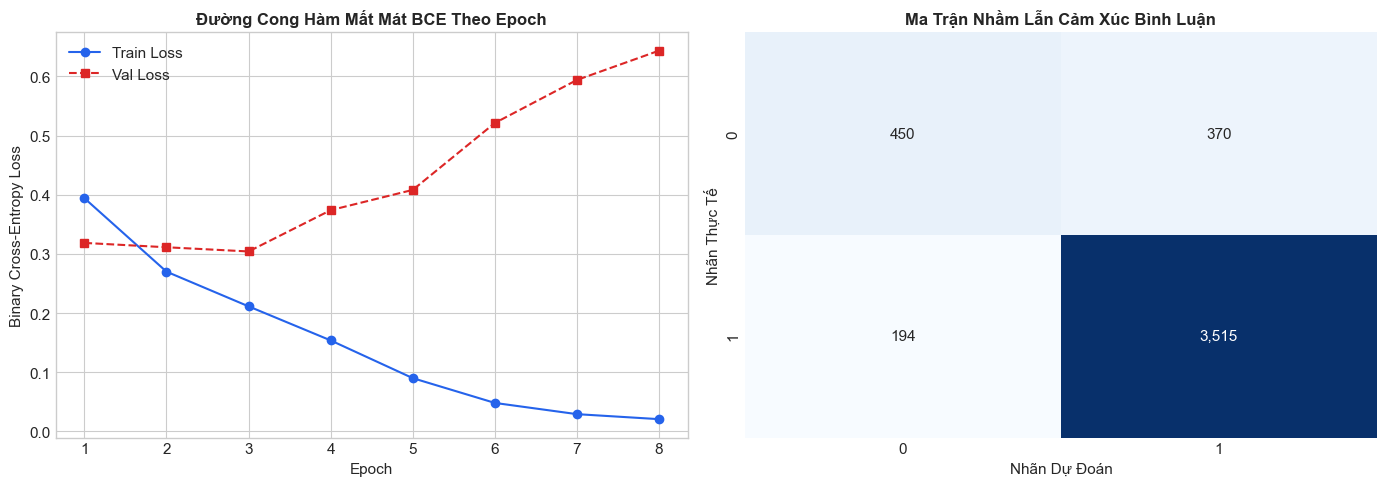

In [8]:
y_prob = model.forward(X_test).ravel()
y_pred = (y_prob >= 0.5).astype(int)

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, zero_division=0)
rec = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
auc = roc_auc_score(y_test, y_prob)

print(f"=== KẾT QUẢ ĐÁNH GIÁ 1D CNN VĂN BẢN (NUMPY FROM SCRATCH) ===")
print(f"• Accuracy : {acc:.4f}")
print(f"• Precision: {prec:.4f}")
print(f"• Recall   : {rec:.4f}")
print(f"• F1-Score : {f1:.4f}")
print(f"• ROC-AUC  : {auc:.4f}")
print(f"• Thời gian: {train_time:.2f} giây")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(range(1, epochs + 1), history["loss"], 'o-', color='#2563eb', label='Train Loss')
axes[0].plot(range(1, epochs + 1), history["val_loss"], 's--', color='#dc2626', label='Val Loss')
axes[0].set_title('Đường Cong Hàm Mất Mát BCE Theo Epoch', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Binary Cross-Entropy Loss')
axes[0].legend()

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', ax=axes[1], cbar=False)
axes[1].set_title('Ma Trận Nhầm Lẫn Cảm Xúc Bình Luận', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Nhãn Dự Đoán')
axes[1].set_ylabel('Nhãn Thực Tế')

plt.tight_layout()
os.makedirs("../reports/figures", exist_ok=True)
plt.savefig("../reports/figures/01_comments_numpy_results.png", dpi=300)
plt.show()


### 7. Lưu Trữ Kết Quả Để Đối Chuẩn Chéo


In [9]:
results_df = pd.DataFrame([{
    "Framework": "NumPy From Scratch",
    "Dataset": "Customer Comments (23.5k)",
    "Accuracy": acc,
    "Precision": prec,
    "Recall": rec,
    "F1": f1,
    "ROC_AUC": auc,
    "Train_Time_Sec": train_time,
    "Epochs": epochs,
    "Batch_Size": batch_size
}])

os.makedirs("../reports", exist_ok=True)
results_df.to_csv("../reports/model_results_numpy.csv", index=False)
print("Đã lưu kết quả thành công vào ../reports/model_results_numpy.csv")
results_df


Đã lưu kết quả thành công vào ../reports/model_results_numpy.csv


,Framework,Dataset,Accuracy,Precision,Recall,F1,ROC_AUC,Train_Time_Sec,Epochs,Batch_Size
0,NumPy From Scratch,Customer Comments (23.5k),0.875469,0.904762,0.947695,0.925731,0.874306,204.22339,8,128
